# Clustering from scratch — k-means, hierarchical, DBSCAN and OPTICS in NumPy

This notebook rebuilds every algorithm that the library lab ([`clustering_lab.ipynb`](clustering_lab.ipynb)) used,
with nothing but NumPy, and checks each one against scikit-learn or SciPy on the same data. The theory is in
[`../README.md`](../README.md).

**How to use it**

1. Run the imports cell first (it also defines the two distance helpers every section uses); then run top to bottom
   (**Run All**, a few seconds). Later sections reuse functions from earlier ones.
2. Each section has the same shape: the algorithm in plain steps (markdown) → the code, commented line by line →
   a **comparison with the library** → a "How to read this" box.
3. Boxes titled **Implementation hurdle** show a real problem you hit when writing this yourself. Each one is
   *demonstrated* with a small failing or surprising case, then fixed.
4. scikit-learn and SciPy are imported **only to check** our answers. No internet needed.

| Section | Algorithm | Checked against |
|---|---|---|
| [1](#sec-1) | k-means (Lloyd's algorithm) and k-means++ starts | `sklearn.cluster.KMeans` |
| [1 · toy](#toy) | Why the start matters: an exact toy with 3 pairs | exact enumeration; `KMeans` from all 20 starts |
| [2](#sec-2) | Choosing k: silhouette and the elbow | `sklearn.metrics.silhouette_score` |
| [3](#sec-3) | Agglomerative clustering with the Lance–Williams update | `scipy.cluster.hierarchy.linkage` |
| [4](#sec-4) | DBSCAN | `sklearn.cluster.DBSCAN` |
| [5](#sec-5) | OPTICS and extracting DBSCAN clusters from it | `sklearn.cluster.OPTICS`, `cluster_optics_dbscan` |
| [Summary](#summary) | what matched, and the hurdles | |

**Two distance helpers** (defined in the imports cell):

* `pairwise_distances(A, B)` uses $\lVert a - b \rVert^2 = \lVert a \rVert^2 - 2\,a \cdot b + \lVert b \rVert^2$: fast and
  memory-light, used for points-to-centroids in k-means.
* `exact_distances(X)` subtracts the points directly: slower but exact, used whenever distances between points are
  compared with each other (hierarchical, DBSCAN, OPTICS). Section 3 shows why exactness matters there.

In [1]:
import heapq
import time
import warnings
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

# scikit-learn / SciPy are imported ONLY to check our answers against theirs; every algorithm below is plain NumPy.
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, OPTICS, KMeans, cluster_optics_dbscan
from sklearn.datasets import load_iris, make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def pairwise_distances(A, B):
    """Euclidean distance between every row of A (n x d) and every row of B (m x d) -> an n x m matrix.

    Uses ||a - b||² = ||a||² - 2 a·b + ||b||², which needs only an n x m matrix in memory, instead of the
    n x m x d array that `A[:, None, :] - B[None, :, :]` would build (see the hurdle in section 1)."""
    squared = (A ** 2).sum(axis=1)[:, None] - 2 * A @ B.T + (B ** 2).sum(axis=1)[None, :]
    return np.sqrt(np.maximum(squared, 0))          # rounding can make a true 0 come out as -1e-15; clip it to 0


def exact_distances(X):
    """All point-to-point distances computed from the differences themselves (n x n x d in memory, fine for a few
    thousand points). Slower than the trick above, but exact to the last digit, which matters when distances TIE
    (see the hurdle in section 3)."""
    return np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))


def plot_clusters(ax, X, labels, title):
    """Scatter 2-D points coloured by cluster label; label -1 (noise) as grey crosses."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")

---

<a id="sec-1"></a>

## 1 · k-means

**README §3.** k-means looks for k centroids that minimise the **inertia** (within-cluster sum of squares):

$$\text{inertia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2, \qquad c(i) = \text{the cluster of point } i$$

**Lloyd's algorithm** alternates two steps, each of which can only lower the inertia:

1. **Assign:** give every point to its nearest centroid. (For fixed centroids this is the best possible assignment.)
2. **Update:** move every centroid to the mean of its points. (For a fixed assignment the mean is the point with the
   smallest sum of squared distances to the group.)

Repeat until no centroid moves. The code below splits this into `assign`, `update` and the loop `kmeans`, and adds
`kmeans_plus_plus` for the starting centroids. The check uses the same data and the same 4 starting centroids for
both our code and scikit-learn (`init=start`, `tol=0` so it also runs until nothing moves).

ours        : inertia 1718.496012, iterations 3
scikit-learn: inertia 1718.496012, iterations 3
same labels: True | largest centroid difference: 3.552713678800501e-15
inertia never went up: True


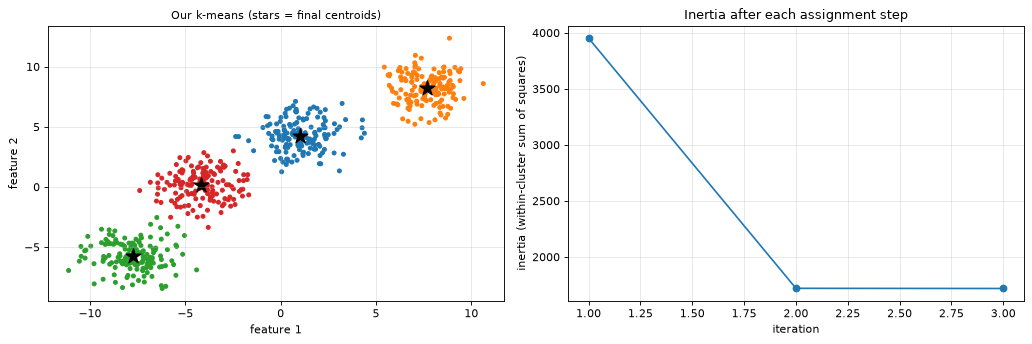

In [2]:
def assign(X, centroids):
    """Step 1 of k-means: the index of the nearest centroid for every point, and that squared distance."""
    distances = pairwise_distances(X, centroids)          # n x k: distance from every point to every centroid
    labels = distances.argmin(axis=1)                      # nearest centroid; ties go to the lower index (like sklearn)
    return labels, distances[np.arange(len(X)), labels] ** 2


def update(X, labels, centroids):
    """Step 2 of k-means: move each centroid to the mean of its points.

    A centroid that lost all its points would get the mean of nothing (NaN). Instead it is moved onto the point that
    is currently worst served (farthest from its own centroid), which is also what scikit-learn does."""
    new = centroids.copy()
    _, squared = assign(X, centroids)
    for k in range(len(centroids)):
        members = X[labels == k]
        if len(members):
            new[k] = members.mean(axis=0)                  # the mean minimises the sum of squared distances
        else:
            worst = squared.argmax()                       # the point paying the most inertia right now
            new[k] = X[worst]
            squared[worst] = 0                             # don't give the same point to two empty clusters
    return new


def kmeans(X, initial_centroids, max_iter=300):
    """Lloyd's algorithm: alternate assign / update until no centroid moves.
    Returns (labels, centroids, inertia after every iteration)."""
    centroids = np.asarray(initial_centroids, dtype=float)
    history = []
    for _ in range(max_iter):
        labels, squared = assign(X, centroids)
        history.append(squared.sum())                      # inertia of the current assignment
        new_centroids = update(X, labels, centroids)
        if np.array_equal(new_centroids, centroids):       # nothing moved: the next assignment would be identical
            break
        centroids = new_centroids
    labels, squared = assign(X, centroids)                 # final assignment to the final centroids
    return labels, centroids, history


def kmeans_plus_plus(X, k, rng):
    """k-means++ starting centroids: the first is a random point; each next one is a random point drawn with
    probability proportional to its SQUARED distance to the nearest centroid chosen so far ("D² sampling")."""
    centroids = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        nearest_sq = pairwise_distances(X, np.array(centroids)).min(axis=1) ** 2   # D(x)² for every point
        centroids.append(X[rng.choice(len(X), p=nearest_sq / nearest_sq.sum())])
    return np.array(centroids)


# Check against scikit-learn: same data, same starting centroids, Lloyd's algorithm, run to full convergence
X_km, _ = make_blobs(600, centers=4, cluster_std=1.2, random_state=3)
start = X_km[np.random.default_rng(11).choice(len(X_km), 4, replace=False)]          # 4 random data points
labels, centroids, history = kmeans(X_km, start)
reference = KMeans(4, init=start, n_init=1, algorithm="lloyd", tol=0).fit(X_km)       # tol=0: stop only when stable

print(f"ours        : inertia {history[-1]:.6f}, iterations {len(history)}")
print(f"scikit-learn: inertia {reference.inertia_:.6f}, iterations {reference.n_iter_}")
print("same labels:", np.array_equal(labels, reference.labels_),
      "| largest centroid difference:", np.abs(centroids - reference.cluster_centers_).max())
print("inertia never went up:", bool(np.all(np.diff(history) <= 1e-9)))
assert np.array_equal(labels, reference.labels_) and np.isclose(history[-1], reference.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_clusters(axes[0], X_km, labels, "Our k-means (stars = final centroids)")
axes[0].scatter(*centroids.T, c="black", marker="*", s=200)
axes[1].plot(range(1, len(history) + 1), history, marker="o")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("inertia (within-cluster sum of squares)")
axes[1].set_title("Inertia after each assignment step")
plt.tight_layout(); plt.show()

> **How to read this**
> * Same starting centroids, same answer: inertia **1718.496012** for both, **3** iterations for both, identical
>   labels, and centroids equal to about 1e-15 (rounding). The `assert` stops the notebook if that ever changes.
> * The inertia never goes up, as the two-step argument above says (right plot). This start happened to be a good one
>   (3 iterations); library Lab 1 shows a random start that needs 15.

> **Implementation hurdle — an empty cluster.** If a starting centroid is far from every point (or loses all its
> points during the run), the update step takes the mean of **zero** points. NumPy returns NaN, and every distance to
> a NaN centroid is NaN from then on. Our `update` instead moves an empty centroid onto the point that is currently
> worst served (largest squared distance to its own centroid), which is also what scikit-learn does.

In [3]:
# A starting centroid far from every point never wins a single point in the first assignment
X_tiny = np.array([[0.0, 0.0], [0.0, 1.0], [10.0, 0.0], [10.0, 1.0]])
bad_start = np.array([[0.0, 0.5], [10.0, 0.5], [100.0, 100.0]])      # the third centroid is miles away

labels_tiny, _ = assign(X_tiny, bad_start)
print("first assignment:", labels_tiny, "-> cluster 2 has", np.sum(labels_tiny == 2), "points")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)                   # numpy warns "mean of empty slice"
    naive = np.array([X_tiny[labels_tiny == k].mean(axis=0) for k in range(3)])  # mean of an empty array
print("naive update, centroid 2:", naive[2], " <- NaN poisons every later distance")
labels_fixed, centroids_fixed, _ = kmeans(X_tiny, bad_start)
print("our update   : final centroids", centroids_fixed.tolist(), "labels", labels_fixed)

first assignment: [0 0 1 1] -> cluster 2 has 0 points
naive update, centroid 2: [nan nan]  <- NaN poisons every later distance
our update   : final centroids [[0.0, 1.0], [10.0, 0.5], [0.0, 0.0]] labels [2 0 1 1]


> **How to read this**
> * Four points in two pairs; the third starting centroid sits at (100, 100), so the first assignment gives it
>   **0** points (`[0 0 1 1]`).
> * The naive update makes that centroid **[nan nan]**.
> * Ours moves it onto (0, 0), one of the two worst-served points (it picks the first of the tie), and the run ends
>   with three real clusters: the left pair split in two, the right pair together.

> **Implementation hurdle — memory.** The obvious way to get every point-to-centroid distance,
> `X[:, None, :] - C[None, :, :]`, builds an n × k × d array before summing over d. With 20,000 points, 100
> centroids and 50 features that array is 100 million numbers. The expansion
> $\lVert x \rVert^2 - 2\,x \cdot c + \lVert c \rVert^2$ needs only the n × k result, and the middle term is one matrix
> product, which NumPy computes very fast.

In [4]:
X_big = np.random.default_rng(SEED).normal(size=(20_000, 50))       # 20,000 points with 50 features
C_big = X_big[:100]                                                 # 100 centroids

broadcast_bytes = X_big.shape[0] * C_big.shape[0] * X_big.shape[1] * 8   # n x k x d float64 array
matrix_bytes = X_big.shape[0] * C_big.shape[0] * 8                       # n x k float64 matrix
start_time = time.perf_counter(); fast = pairwise_distances(X_big, C_big); t_fast = time.perf_counter() - start_time
start_time = time.perf_counter()
slow = np.sqrt(((X_big[:, None, :] - C_big[None, :, :]) ** 2).sum(axis=2))   # the "obvious" broadcasting version
t_slow = time.perf_counter() - start_time
print(f"broadcasting builds a {broadcast_bytes / 1e6:.0f} MB array, the expansion trick a {matrix_bytes / 1e6:.0f} MB one")
print(f"time: broadcasting {t_slow:.2f} s, expansion trick {t_fast:.3f} s; largest difference {np.abs(fast - slow).max():.1e}")

broadcasting builds a 800 MB array, the expansion trick a 16 MB one
time: broadcasting 0.18 s, expansion trick 0.007 s; largest difference 2.4e-07


> **How to read this**
> * Broadcasting builds an **800 MB** temporary array; the expansion trick only the **16 MB** answer.
> * It is also much faster (see the printed times; yours will differ). The results agree to about **2e-7**. That
>   small rounding error is harmless for k-means, but section 3 shows where it isn't.

### k-means++ starting centroids

**README §3.4.** Pick the first centroid: a data point chosen uniformly at random. Then, repeatedly, pick a data point at random with probability
proportional to $D(x)^2$, the squared distance from $x$ to the nearest centroid chosen so far. Points far from every
existing centroid are likely picks, so the starts spread over the data. Below: 100 runs of **our** k-means from random
starts and 100 from our k-means++ starts, on the 10 blobs of library Lab 2.

random    : median inertia  1667.3, worst  9946.2, within 1 % of the best: 3%
k-means++ : median inertia   715.8, worst  2741.1, within 1 % of the best: 29%


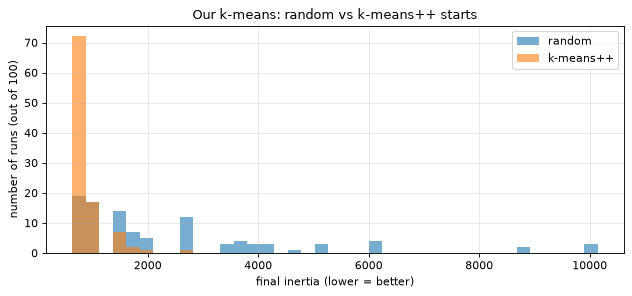

In [5]:
# 100 runs from random starts vs 100 runs from k-means++ starts, using OUR k-means, on 10 blobs (as in library Lab 2)
X_pp, _ = make_blobs(1000, centers=10, cluster_std=0.6, center_box=(-12, 12), random_state=42)
finals = {"random": [], "k-means++": []}
for seed in range(100):
    rng = np.random.default_rng(seed)
    finals["random"].append(kmeans(X_pp, X_pp[rng.choice(len(X_pp), 10, replace=False)])[2][-1])
    finals["k-means++"].append(kmeans(X_pp, kmeans_plus_plus(X_pp, 10, np.random.default_rng(seed)))[2][-1])
best = min(min(v) for v in finals.values())
for name, values in finals.items():
    values = np.array(values)
    print(f"{name:10s}: median inertia {np.median(values):7.1f}, worst {values.max():7.1f}, "
          f"within 1 % of the best: {np.mean(values <= best * 1.01):.0%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(best * 0.98, max(max(v) for v in finals.values()) * 1.02, 40)
for name, values in finals.items():
    ax.hist(values, bins=bins, alpha=0.6, label=name)
ax.set_xlabel("final inertia (lower = better)"); ax.set_ylabel("number of runs (out of 100)")
ax.set_title("Our k-means: random vs k-means++ starts"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * **Random starts:** median inertia **1667.3**, worst **9946.2**, only **3 %** of runs within 1 % of the best.
> * **Our k-means++:** median **715.8**, worst **2741.1**, **29 %** of runs within 1 % of the best. Far better.
> * scikit-learn's k-means++ reached the best in 50 % of runs in library Lab 2. It uses the **greedy** variant: at each
>   step it draws $2 + \ln k$ candidates and keeps the one that lowers the inertia most. Same idea, a little more work,
>   fewer bad starts.

<a id="toy"></a>

### Why the start matters: an exact toy (3 pairs)

The histogram above shows *that* random starts end worse. This toy is small enough to show *why*, exactly: every
possible start can be listed, run, and given its probability.

**Setup.** Six points on a line in three pairs X, Y, Z; inside each pair the two points are **s** apart. **Y's left
point is the origin**, and both gaps are measured **edge to edge**, between the facing points:

* Y = {0, s}
* Z = {s + Δ, 2s + Δ}: **Δ** is the gap from Y's right point to Z's left point;
* X = {−D − s, −D}: **D** is the gap from X's right point to the origin. X is far away: **D = 4Δ**.

So the pair centres are $-D - \tfrac{s}{2}$, $\tfrac{s}{2}$ and $\tfrac{3s}{2} + \Delta$: centre to centre, X–Y is
$D + s$ and Y–Z is $\Delta + s$. Write $r = \Delta / s$ (the Y–Z gap measured in pair widths); every formula below
depends on the gap only through $1 + r = (\Delta + s)/s$, the Y–Z centre distance in pair widths. The code uses
$s = 1$, $\Delta = 10$, $D = 40$, so $r = 10$ and the points are −41, −40, 0, 1, 11, 12. The gaps are unequal on
purpose: with equal gaps Y would sit exactly halfway between X and Z, and the result would depend on how ties are
broken.

```mermaid
flowchart LR
    subgraph line["3 pairs, each s wide"]
        direction LR
        X["X: −D−s … −D"] -- "D" --- Y["Y: 0 … s"] -- "Δ" --- Z["Z: s+Δ … 2s+Δ"]
    end
    subgraph opt["Optimum · inertia = 3s²/2"]
        direction LR
        O1(("c₁ = −D − s/2")) ~~~ O2(("c₂ = s/2")) ~~~ O3(("c₃ = 3s/2 + Δ"))
    end
    subgraph stuck["Stuck · inertia = s² + (Δ+s)²"]
        direction LR
        S1(("c₁ = −D − s")) ~~~ S2(("c₂ = −D")) ~~~ S3(("c₃ = s + Δ/2 for Y and Z"))
    end
    line -- "one start in each pair" --> opt
    line -- "two starts in X" --> stuck
```

(The diagram renders in JupyterLab ≥ 4.1 and VS Code; GitHub may show it as text. The first code cell below draws the
same picture with matplotlib.)

**The two endings, as equations.** A pair split between two centroids costs 0 (each point is its own centroid). A
pair under one centroid costs $2\,(s/2)^2 = s^2/2$.

$$\text{optimum (one centroid per pair)} = 3 \cdot \frac{s^2}{2} = \frac{3s^2}{2}$$

In the stuck ending X is split and one centroid serves Y ∪ Z. That centroid is the mean of 0, s, s + Δ, 2s + Δ, i.e.
$s + \Delta/2$, halfway between the two pair centres, which are $\Delta + s$ apart. Each of the four points is
$\frac{\Delta + s}{2} \pm \frac{s}{2}$ from it:

$$\text{stuck} = 0 + 2\left[\left(\tfrac{\Delta + s}{2} + \tfrac{s}{2}\right)^2 + \left(\tfrac{\Delta + s}{2} - \tfrac{s}{2}\right)^2\right] = s^2 + (\Delta + s)^2 = s^2\left[1 + (1 + r)^2\right]$$

So the stuck ending is $\frac{s^2 + (\Delta + s)^2}{3s^2/2} = \frac{2}{3}\left[1 + (1 + r)^2\right]$ times the optimum:
**81×** at $r = 10$, and it grows without limit as the pairs move apart.

<details>
<summary><b>Why Lloyd's cannot leave the stuck state</b> (click to expand)</summary>

Lloyd's stops when (1) every point is nearest its own centroid and (2) every centroid is the mean of its points.

* (2) holds by construction: each X point is its own centroid, and $c_3 = s + \Delta/2$ is the mean of Y ∪ Z.
* (1): the X points are at distance 0 from their centroids. The Y ∪ Z points farthest from $c_3$ are the outer ones,
  0 and $2s + \Delta$, both $s + \Delta/2$ away. The X centroid nearest to Y is X's right point at $-D$, which is $D$
  from the origin. So nothing moves as long as $s + \Delta/2 < D$; with $D = 4\Delta$ that is $\Delta > 2s/7$ —
  always, for real pairs.

Moving c₂ from X over to Y would lower the inertia a lot, but no single assign or update step makes that jump: Lloyd's
only ever moves a centroid to the mean of the points nearest to it.
</details>

points (x only): [-41. -40.   0.   1.  11.  12.]
good start -> centroids [-40.5   0.5  11.5], inertia 1.5   (formula 3s²/2 = 1.5)
bad start  -> centroids [-41. -40.   6.], inertia 122.0 (formula s² + (Δ + s)² = 122.0)


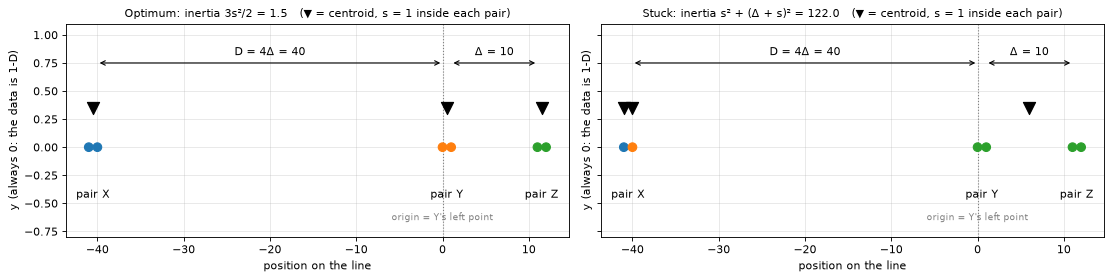

In [6]:
from itertools import combinations


def three_pairs(r, s=1.0):
    """The 6-point toy: pairs X, Y, Z on a line (stored as 2-D points with y = 0 so every helper above works).
    Y's left point is the origin. Δ = r·s is the EDGE-TO-EDGE gap from Y's right point to Z's left point, and
    D = 4Δ the edge-to-edge gap from X's right point to the origin. Returns (points, pair index 0/1/2)."""
    gap, far = r * s, 4 * r * s                                       # Δ and D
    x = np.array([-far - s, -far,                                     # X = {-D - s, -D}
                  0.0, s,                                             # Y = {0, s}: the origin is Y's left point
                  s + gap, 2 * s + gap])                              # Z = {s + Δ, 2s + Δ}
    return np.column_stack([x, np.zeros(6)]), np.repeat([0, 1, 2], 2)


r, s = 10.0, 1.0                                                     # Δ = r·s = 10, D = 4Δ = 40
X_toy, pair = three_pairs(r, s)
gap, far = r * s, 4 * r * s
opt_formula, stuck_formula = 3 * s**2 / 2, s**2 + (gap + s)**2       # the two equations above

# Run OUR kmeans from one good start (one point per pair) and one bad start (both X points + one Y point)
good_labels, good_c, good_hist = kmeans(X_toy, X_toy[[0, 2, 4]])
bad_labels, bad_c, bad_hist = kmeans(X_toy, X_toy[[0, 1, 2]])
print(f"points (x only): {X_toy[:, 0]}")
print(f"good start -> centroids {good_c[:, 0]}, inertia {good_hist[-1]:.1f}   (formula 3s²/2 = {opt_formula:.1f})")
print(f"bad start  -> centroids {bad_c[:, 0]}, inertia {bad_hist[-1]:.1f} (formula s² + (Δ + s)² = {stuck_formula:.1f})")
assert np.isclose(good_hist[-1], opt_formula) and np.isclose(bad_hist[-1], stuck_formula)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, labels, cents, title in [(axes[0], good_labels, good_c, f"Optimum: inertia 3s²/2 = {opt_formula:.1f}"),
                                 (axes[1], bad_labels, bad_c, f"Stuck: inertia s² + (Δ + s)² = {stuck_formula:.1f}")]:
    ax.scatter(X_toy[:, 0], X_toy[:, 1], c=labels, cmap="tab10", vmin=0, vmax=9, s=60, zorder=3)   # colour = cluster
    ax.scatter(cents[:, 0], cents[:, 1] + 0.35, c="black", marker="v", s=120, zorder=3)            # centroid markers
    for name, centre in zip("XYZ", [-far - s / 2, s / 2, 1.5 * s + gap]):
        ax.text(centre, -0.45, f"pair {name}", ha="center", fontsize=10)                          # pair names
    ax.axvline(0, color="gray", ls=":", lw=1)                                                     # the origin
    ax.text(0, -0.65, "origin = Y's left point", ha="center", fontsize=8, color="gray")
    ax.annotate("", xy=(-far, 0.75), xytext=(0, 0.75), arrowprops=dict(arrowstyle="<->"))        # D: X's right to 0
    ax.text(-far / 2, 0.82, f"D = 4Δ = {far:.0f}", ha="center")
    ax.annotate("", xy=(s, 0.75), xytext=(s + gap, 0.75), arrowprops=dict(arrowstyle="<->"))     # Δ: Y's right to Z's left
    ax.text(s + gap / 2, 0.82, f"Δ = {gap:.0f}", ha="center")
    ax.set_ylim(-0.8, 1.1); ax.set_title(title + "   (▼ = centroid, s = 1 inside each pair)", fontsize=10)
    ax.set_xlabel("position on the line"); ax.set_ylabel("y (always 0: the data is 1-D)")
plt.tight_layout(); plt.show()

> **How to read this**
> * The points are **−41, −40, 0, 1, 11, 12**: the origin is Y's left point, D = 40 and Δ = 10 are edge-to-edge gaps.
> * Our `kmeans` from the start (one point per pair) ends with centroids at **−40.5, 0.5, 11.5** (the pair centres)
>   and inertia **1.5** = 3s²/2.
> * From the start (both X points + one Y point) it ends with centroids at **−41, −40, 6** and inertia
>   **122.0** = s² + (Δ + s)² = 1 + 121. Both match the equations (the `assert` checks). Same data, same algorithm:
>   only the start differs.
> * In the right plot Y and Z share one colour (one cluster) while X's two points are split, as in the diagram.

#### All 20 random starts

scikit-learn's `init="random"` picks 3 distinct data points, all equally likely: $\binom{6}{3} = 20$ possible starts,
each with probability 1/20. Only $2 \cdot 2 \cdot 2 = 8$ of them (**40 %**) have one point in each pair. The other 12
put two points in one pair and one in another (three in one pair is impossible: a pair has only 2 points).

Below, **every** start is run through our `kmeans` and checked against scikit-learn's `KMeans` with the same start.
Iterations are counted like scikit-learn's `n_iter_`, including the last pass that confirms nothing moves, so **2** is
the minimum here.

<details>
<summary><b>Which bad starts recover, and which get stuck</b> (click to expand)</summary>

Call the pair with two starting centroids **P**, the pair with one **Q**, and the pair with none **R**. In the first
assignment, R's points go to the nearest centroid:

* **R joins Q's centroid → stuck.** Q and R merge under one centroid while P stays split: the stuck state above. This
  happens when P = X: Y and Z are neighbours, so the uncovered one goes to the other's centroid.
  *Trace from (−41, −40, 0):* Y and Z all go to the centroid at 0 → $c_3$ = mean(Y ∪ Z) = $s + \Delta/2$ = 6 →
  nothing changes. Final inertia $s^2 + (\Delta + s)^2$.
* **R joins one of P's centroids → recovers.** That centroid is dragged out towards R, so the P point it had is now
  nearer its partner's centroid and moves back. Lloyd's ends at the optimum.
  *Trace from (0, s, −D − s):* Z (at Δ and Δ + s from Y's right point) goes to the centroid at s →
  $c_2 = \frac{s + (s + \Delta) + (2s + \Delta)}{3} = \frac{4s + 2\Delta}{3}$ (= 8 here) → the point s is now nearer
  the centroid at 0 (distance s) than $c_2$ (distance $\frac{s + 2\Delta}{3}$, true whenever $\Delta > s$) → it moves
  back, and the centroids land on the three pair centres.
* *(2 in Z, 1 in Y)* needs one more pass: X first joins Y's centroid (D or D + s away, vs D + s + Δ to Z), which drags
  that centroid to $-D/2$; then Y's right point is nearer Z's left centroid (Δ away, vs $s + D/2$) and moves there,
  and the chain ends at the optimum. With other gaps (e.g. D = Δ) this start gets stuck instead.
</details>

In [7]:
def start_class(start, pair):
    """Name a start by which pairs its 3 points come from: 'one per pair' or e.g. '2 in X, 1 in Y'."""
    picked = list(pair[list(start)])
    if len(set(picked)) == 3:
        return "one per pair"
    doubled = max(set(picked), key=picked.count)                     # the pair that got two starting centroids
    single = [p for p in picked if p != doubled][0]
    return f"2 in {'XYZ'[doubled]}, 1 in {'XYZ'[single]}"


def run_all_starts(X, pair):
    """Run OUR kmeans from every one of the C(6,3) = 20 possible 3-point starts.
    Returns {frozenset(start indices): (class name, final inertia, iterations)}."""
    results = {}
    for start in combinations(range(len(X)), 3):
        _, _, history = kmeans(X, X[list(start)])
        results[frozenset(start)] = (start_class(start, pair), history[-1], len(history))
    return results


runs = run_all_starts(X_toy, pair)

# Check every start against scikit-learn (same start, Lloyd, tol=0)
for start, (_, inertia, _) in runs.items():
    ref = KMeans(3, init=X_toy[sorted(start)], n_init=1, algorithm="lloyd", tol=0).fit(X_toy)
    assert np.isclose(inertia, ref.inertia_)

print(f"{'start class':16s} {'count':>5s} {'final inertia':>14s} {'iterations':>11s}")
for name in sorted({c for c, _, _ in runs.values()}, key=lambda c: (c != "one per pair", c)):
    group = [(inr, it) for c, inr, it in runs.values() if c == name]
    print(f"{name:16s} {len(group):5d} {group[0][0]:14.1f} {group[0][1]:11d}")
inertias = np.array([inr for _, inr, _ in runs.values()])
iterations = np.array([it for _, _, it in runs.values()])
print(f"\nrandom init (each of the 20 starts has probability 1/20):")
print(f"  P(optimum) = {np.mean(np.isclose(inertias, opt_formula)):.2f}, "
      f"E[inertia] = {inertias.mean():.2f} (formula s²(7 + (1 + r)²)/5 = {s**2 * (7 + (1 + r)**2) / 5:.2f}), "
      f"E[iterations] = {iterations.mean():.2f}")

start class      count  final inertia  iterations
one per pair         8            1.5           2
2 in X, 1 in Y       2          122.0           2
2 in X, 1 in Z       2          122.0           2
2 in Y, 1 in X       2            1.5           3
2 in Y, 1 in Z       2            1.5           3
2 in Z, 1 in X       2            1.5           3
2 in Z, 1 in Y       2            1.5           4

random init (each of the 20 starts has probability 1/20):
  P(optimum) = 0.80, E[inertia] = 25.60 (formula s²(7 + (1 + r)²)/5 = 25.60), E[iterations] = 2.50


> **How to read this**
> * The **4** starts with both centroids in X (2 in X, 1 in Y or Z) end **stuck at 122.0**; all **16** others end at
>   the optimum **1.5**, including 8 of the 12 bad starts, which Lloyd's repairs.
> * So random init reaches the optimum with probability **0.80** for every r, and its expected inertia
>   **25.60** = s²[7 + (1 + r)²]/5 = (1/5)[s² + (Δ + s)²] + (4/5)(3s²/2) grows like r².
> * Iterations: the starts with one point per pair need **2**, the repaired ones **3–4**. The stuck ones also need
>   only **2**: converging fast is not the same as converging well. On average random init takes **2.50**.

#### The same starts under k-means++, with exact probabilities

k-means++ picks the first point with probability 1/6, the second with $D(x)^2 / \sum D^2$, and the third the same way
after updating $D(x)$. (Here $D(x)$ is k-means++'s distance to the nearest chosen point, not the gap D.)
`kpp_start_probabilities` walks all $6 \cdot 5 \cdot 4 = 120$ ordered pick sequences and adds up the probability of
each 3-point start; each start's ending is already known from the 20 runs above. A Monte Carlo run of the notebook's
own `kmeans_plus_plus` checks the result.

<details>
<summary><b>Where P(stuck) ≈ 0.488 / (1 + r)² comes from</b> (click to expand)</summary>

Stuck needs both X points among the three picks. Work to leading order for well-separated pairs, in units of the
Y–Z centre distance $g = \Delta + s$ (so $g/s = 1 + r$): Y–Z is $g$ apart, X–Y about $4g$, X–Z about $5g$.

* **One X point and one Y/Z point first, then X's partner.** After the first two picks, X's partner has
  $D(x)^2 = s^2$, the partner in the covered Y/Z pair has $s^2$, and the two points of the uncovered pair about $g^2$
  each. So the third pick is X's partner with probability $\approx s^2 / (2g^2) = 1/(2(1 + r)^2)$.
  * First pick in X (probability 2/6), second anywhere in Y ∪ Z (≈ 1): contributes
    $\frac{1}{3} \cdot \frac{1}{2(1 + r)^2}$.
  * First pick in Y (2/6), second in X ($\approx \frac{2 \cdot 16}{2 \cdot 16 + 2} = \frac{16}{17}$): contributes
    $\frac{1}{3} \cdot \frac{16}{17} \cdot \frac{1}{2(1 + r)^2}$. First in Z similarly, with $\frac{25}{26}$.
* **X then X's partner straight away:** $\frac{1}{3} \cdot \frac{1}{82 (1 + r)^2}$ (sum of $D(x)^2$ from an X point
  $\approx 2 \cdot 16g^2 + 2 \cdot 25g^2 = 82g^2$), after which any third pick is stuck.

Adding up: $P(\text{stuck}) \approx \frac{1}{3}\left[\frac{1}{2} + \frac{16}{34} + \frac{25}{52} + \frac{1}{82}\right]\frac{1}{(1 + r)^2} \approx \frac{0.488}{(1 + r)^2}$.
(Writing $r^2$ instead of $(1 + r)^2$ has the same limit but is off by about 20 % at $r = 10$: the distances that
matter are between pair centres, $\Delta + s$, not edges.) So the stuck ending costs
$s^2[1 + (1 + r)^2]$ but happens with probability ∝ $1/(1 + r)^2$: its share of the expected inertia stays about
$0.49\,s^2$ however far apart the pairs are.
</details>

In [8]:
def kpp_start_probabilities(X, k):
    """EXACT probability of every set of k starting points under (plain) k-means++, by walking every ordered
    sequence of picks: first pick 1/n, every next pick D(x)²/ΣD(x)² with D updated after each pick."""
    probabilities = {}

    def walk(chosen, prob):
        if len(chosen) == k:                                          # a complete start: add its probability
            key = frozenset(chosen)
            probabilities[key] = probabilities.get(key, 0.0) + prob
            return
        d2 = pairwise_distances(X, X[chosen]).min(axis=1) ** 2        # D(x)² to the nearest chosen point
        d2[chosen] = 0.0                                              # chosen points can't be picked (clip rounding)
        for i in np.flatnonzero(d2 > 0):                              # every possible next pick ...
            walk(chosen + [i], prob * d2[i] / d2.sum())               # ... with its D² probability

    for first in range(len(X)):
        walk([first], 1 / len(X))                                     # the first pick is uniform
    return probabilities


kpp_prob = kpp_start_probabilities(X_toy, 3)
print(f"probabilities add up to {sum(kpp_prob.values()):.12f}")

print(f"\n{'start class':16s} {'P(random)':>9s} {'P(k-means++)':>13s} {'final inertia':>14s} {'iterations':>11s}")
for name in sorted({c for c, _, _ in runs.values()}, key=lambda c: (c != "one per pair", c)):
    members = [st for st, (c, _, _) in runs.items() if c == name]
    inertia, its = runs[members[0]][1], runs[members[0]][2]
    print(f"{name:16s} {len(members) / 20:9.2f} {sum(kpp_prob.get(st, 0) for st in members):13.5f} "
          f"{inertia:14.1f} {its:11d}")

p_opt = sum(p for st, p in kpp_prob.items() if np.isclose(runs[st][1], opt_formula))
e_inertia = sum(p * runs[st][1] for st, p in kpp_prob.items())
e_iter = sum(p * runs[st][2] for st, p in kpp_prob.items())
print(f"\nk-means++: P(optimum) = {p_opt:.5f}, P(stuck) = {1 - p_opt:.5f} (leading term 0.488/(1 + r)² = {0.488 / (1 + r)**2:.5f}), "
      f"E[inertia] = {e_inertia:.3f}, E[iterations] = {e_iter:.3f}")

# Monte Carlo check with the notebook's own kmeans_plus_plus sampler
rng = np.random.default_rng(SEED)
draws = 100_000
stuck = 0
for _ in range(draws):
    start = kmeans_plus_plus(X_toy, 3, rng)
    idx = frozenset(pairwise_distances(start, X_toy).argmin(axis=1))  # which data points were picked
    stuck += not np.isclose(runs[idx][1], opt_formula)
print(f"Monte Carlo, {draws:,} k-means++ starts: P(stuck) = {stuck / draws:.5f}")

probabilities add up to 1.000000000000

start class      P(random)  P(k-means++)  final inertia  iterations
one per pair          0.40       0.99186            1.5           2
2 in X, 1 in Y        0.10       0.00182          122.0           2
2 in X, 1 in Z        0.10       0.00218          122.0           2
2 in Y, 1 in X        0.10       0.00189            1.5           3
2 in Y, 1 in Z        0.10       0.00002            1.5           3
2 in Z, 1 in X        0.10       0.00221            1.5           3
2 in Z, 1 in Y        0.10       0.00001            1.5           4

k-means++: P(optimum) = 0.99600, P(stuck) = 0.00400 (leading term 0.488/(1 + r)² = 0.00403), E[inertia] = 1.982, E[iterations] = 2.004


Monte Carlo, 100,000 k-means++ starts: P(stuck) = 0.00412


> **How to read this**
> * The exact probabilities add up to **1**. One point per pair now has probability **0.99186** (random: 0.40). The
>   two stuck classes (**0.00182** and **0.00218**) give P(stuck) = **0.00400** (random: 0.20), close to the leading
>   term 0.488/(1 + r)² = **0.00403**.
> * Expected final inertia **1.982** (random: 25.60), expected iterations **2.004** (random: 2.50).
> * Monte Carlo with `kmeans_plus_plus`: P(stuck) = **0.00412** from 100,000 starts. With that many draws the random
>   error is about ±0.0002, so this agrees with the exact 0.00400.
> * k-means++ still fails sometimes (about 1 start in 250 here). scikit-learn's greedy candidates and `n_init`
>   restarts make that rarer.

#### Moving the pairs apart

The same exact calculation for every r from 3 to 100 (D = 4Δ throughout). Each r reruns all 20 starts and all 120
pick sequences, and checks that no start ends below 3s²/2, so that really is the optimum.

r =   3: P(optimum) random 0.80, k-means++ 0.97092 | E[inertia]/optimum random     3.07, k-means++ 1.301
r =  10: P(optimum) random 0.80, k-means++ 0.99600 | E[inertia]/optimum random    17.07, k-means++ 1.321
r = 100: P(optimum) random 0.80, k-means++ 0.99995 | E[inertia]/optimum random  1361.07, k-means++ 1.325


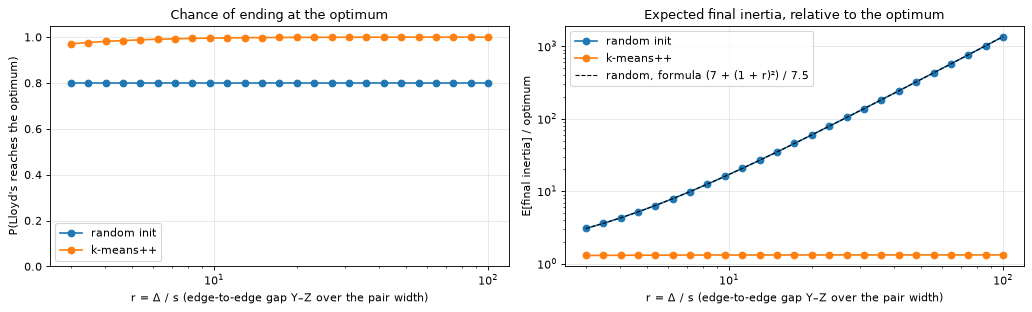

In [9]:
def compare_inits(r, s=1.0):
    """P(optimum) and E[final inertia] / optimum under random init and k-means++, exactly, for one r."""
    X, pair = three_pairs(r, s)
    runs_r = run_all_starts(X, pair)
    opt = 3 * s**2 / 2
    assert min(inr for _, inr, _ in runs_r.values()) >= opt - 1e-9   # no start beats 3s²/2: it is the optimum
    probs = kpp_start_probabilities(X, 3)
    random_reach = np.mean([np.isclose(inr, opt) for _, inr, _ in runs_r.values()])
    random_ratio = np.mean([inr for _, inr, _ in runs_r.values()]) / opt
    kpp_reach = sum(p for st, p in probs.items() if np.isclose(runs_r[st][1], opt))
    kpp_ratio = sum(p * runs_r[st][1] for st, p in probs.items()) / opt
    return random_reach, kpp_reach, random_ratio, kpp_ratio


r_grid = np.geomspace(3, 100, 25)                                    # r < 3: the pairs stop being clear clusters
table = np.array([compare_inits(rv) for rv in r_grid])
for rv in [3, 10, 100]:
    rr, kr, rq, kq = compare_inits(rv)
    print(f"r = {rv:3d}: P(optimum) random {rr:.2f}, k-means++ {kr:.5f} | "
          f"E[inertia]/optimum random {rq:8.2f}, k-means++ {kq:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(r_grid, table[:, 0], marker="o", label="random init")
axes[0].plot(r_grid, table[:, 1], marker="o", label="k-means++")
axes[0].set_xscale("log"); axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel("r = Δ / s (edge-to-edge gap Y–Z over the pair width)"); axes[0].set_ylabel("P(Lloyd's reaches the optimum)")
axes[0].set_title("Chance of ending at the optimum"); axes[0].legend()
axes[1].plot(r_grid, table[:, 2], marker="o", label="random init")
axes[1].plot(r_grid, table[:, 3], marker="o", label="k-means++")
axes[1].plot(r_grid, (7 + (1 + r_grid)**2) / 7.5, "k--", lw=1, label="random, formula (7 + (1 + r)²) / 7.5")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("r = Δ / s (edge-to-edge gap Y–Z over the pair width)"); axes[1].set_ylabel("E[final inertia] / optimum")
axes[1].set_title("Expected final inertia, relative to the optimum"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * **Left:** random init reaches the optimum with probability **0.80** at every r; k-means++ goes from **0.971** at
>   r = 3 to **0.99995** at r = 100.
> * **Right (log scales):** random init's expected inertia over the optimum grows like r² and sits on the formula
>   [7 + (1 + r)²]/7.5: **3.07** at r = 3, **17.07** at r = 10, **1361.07** at r = 100. k-means++ stays flat at about
>   **1.3** (1.301, 1.321, 1.325): the stuck ending gets worse but rarer at the same rate.

**What can be proven in general, and what can't**

* **k-means++ has a guarantee.** Arthur & Vassilvitskii (2007) proved that for *every* dataset the k-means++
  seeding alone has expected inertia at most $8(\ln k + 2)$ times the optimum (about 24.8× for k = 3); Lloyd's
  only lowers it from there. The toy's 1.3× is far inside that worst-case bound.
* **Random init has no such guarantee.** The toy is a counterexample: its expected inertia over the optimum,
  $[7 + (1 + r)^2]/7.5$, grows without limit as r grows.
* **"k-means++ needs fewer iterations" is a tendency, not a theorem.** Lloyd's can need exponentially many iterations
  in the worst case (Vattani 2011) and a polynomial number in the smoothed sense (Arthur, Manthey & Röglin 2009),
  whatever the start. In the toy the extra iterations of random init are Lloyd's repairing bad starts, and the worst
  starts converge fastest.

---

<a id="sec-2"></a>

## 2 · Choosing k: the silhouette and the elbow

**README §3.5.** For every point $i$:

* $a(i)$ = mean distance to the **other** points of its own cluster (divide by $n_\text{own} - 1$, because the point's
  zero distance to itself doesn't count);
* $b(i)$ = for every other cluster, the mean distance from $i$ to its points; take the smallest;
* $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$, and $s(i) = 0$ for a point alone in its cluster.

The mean of $s(i)$ is the silhouette score. The **elbow** is found with the chord rule from library Lab 3: rescale the
inertia curve to 0–1 on both axes and take the k farthest from the straight line between its two ends. Each k uses
the best of 5 runs of our k-means with k-means++ starts.

inertia per k : [20725. 10691.  5780.  1136.  1019.   916.   799.   774.]
silhouette ours   : [0.499 0.594 0.769 0.665 0.546 0.46  0.437]
silhouette sklearn: [0.499 0.594 0.769 0.665 0.546 0.46  0.437]
elbow (chord rule) k = 4, best silhouette k = 4


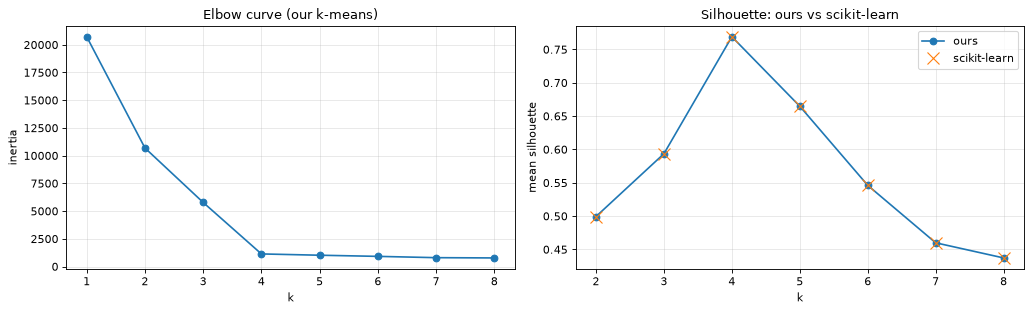

In [10]:
def silhouette_values(X, labels):
    """Silhouette s(i) = (b - a) / max(a, b) for every point, where
    a = mean distance to the other points of its own cluster, b = smallest mean distance to another cluster."""
    D = pairwise_distances(X, X)                       # all point-to-point distances, n x n
    clusters = np.unique(labels)
    s = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]
        if own.sum() == 1:                             # a cluster of one: s(i) is defined as 0
            continue
        a = D[i, own].sum() / (own.sum() - 1)          # divide by n_own - 1: the distance to itself (0) is excluded
        b = min(D[i, labels == c].mean() for c in clusters if c != labels[i])
        s[i] = (b - a) / max(a, b)
    return s


def knee_by_chord(ks, values):
    """The k whose point lies farthest from the straight line joining the first and last points (the elbow)."""
    ks, values = np.asarray(ks, float), np.asarray(values, float)
    x = (ks - ks[0]) / (ks[-1] - ks[0])                         # rescale both axes to 0..1 so the units don't matter
    v = (values - values.min()) / (values.max() - values.min())
    chord = v[0] + (v[-1] - v[0]) * x                            # height of the straight line at each k
    return int(ks[np.argmax(np.abs(chord - v))])


X_k, _ = make_blobs(400, centers=[[-5, -5], [5, -5], [-5, 5], [5, 5]], cluster_std=1.2, random_state=1)
ks = list(range(1, 9))
inertias, sil_ours, sil_sklearn = [], [], []
for k in ks:
    rng = np.random.default_rng(SEED)
    runs = [kmeans(X_k, kmeans_plus_plus(X_k, k, rng)) for _ in range(5)]    # best of 5 k-means++ runs
    lab, cen, hist = min(runs, key=lambda run: run[2][-1])
    inertias.append(hist[-1])
    if k > 1:
        sil_ours.append(silhouette_values(X_k, lab).mean())
        sil_sklearn.append(silhouette_score(X_k, lab))
print("inertia per k :", np.round(inertias, 0))
print("silhouette ours   :", np.round(sil_ours, 4))
print("silhouette sklearn:", np.round(sil_sklearn, 4))
print(f"elbow (chord rule) k = {knee_by_chord(ks, inertias)}, best silhouette k = {ks[1:][int(np.argmax(sil_ours))]}")
assert np.allclose(sil_ours, sil_sklearn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow curve (our k-means)")
axes[1].plot(ks[1:], sil_ours, marker="o", label="ours"); axes[1].plot(ks[1:], sil_sklearn, "x", ms=10, label="scikit-learn")
axes[1].set_xlabel("k"); axes[1].set_ylabel("mean silhouette"); axes[1].set_title("Silhouette: ours vs scikit-learn")
axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Our silhouette equals scikit-learn's at every k (**0.499, 0.594, 0.769, 0.665, …**); the `assert` checks all of
>   them.
> * Both rules pick **k = 4**, the four blobs: the inertia drops steeply until k = 4 (20725 → 1136) and slowly after.

---

<a id="sec-3"></a>

## 3 · Agglomerative (hierarchical) clustering

**README §4.** Start with every point as its own cluster. Repeat n − 1 times: find the two **closest clusters**, merge
them, and record the merge as one row of the **linkage matrix** `[cluster 1, cluster 2, distance, new size]` (SciPy's
format, so SciPy's `dendrogram` can draw our result).

"Closest" depends on the linkage. Recomputing it from all the points after every merge would be slow, so we use the
**Lance–Williams update**: the distance from the merged cluster $A \cup B$ to any other cluster $C$ follows from the
three distances we already have, $d(A, C)$, $d(B, C)$ and $d(A, B)$:

| Linkage | $d(A \cup B,\ C)$ |
|---|---|
| single | $\min\big(d(A,C),\ d(B,C)\big)$ |
| complete | $\max\big(d(A,C),\ d(B,C)\big)$ |
| average | $\dfrac{\lvert A\rvert\, d(A,C) + \lvert B\rvert\, d(B,C)}{\lvert A\rvert + \lvert B\rvert}$ |
| ward | $\sqrt{\dfrac{(\lvert A\rvert + \lvert C\rvert)\, d(A,C)^2 + (\lvert B\rvert + \lvert C\rvert)\, d(B,C)^2 - \lvert C\rvert\, d(A,B)^2}{\lvert A\rvert + \lvert B\rvert + \lvert C\rvert}}$ |

The ward formula is SciPy's version on plain (not squared) distances. Each merge scans all living pairs, so this naive
version costs about $n^3$ operations: fine for hundreds of points, too slow for tens of thousands. Data: the 150 iris
flowers (4 measurements, all in cm, so no scaling needed).

method     largest merge-height difference vs SciPy   same 3-cluster partition (ARI = 1)   seconds (ours / SciPy)
single          0.0e+00                              True                               0.01 / 0.0002
complete        0.0e+00                              True                               0.01 / 0.0002
average         8.9e-16                              True                               0.01 / 0.0002
ward            1.8e-15                              True                               0.02 / 0.0002


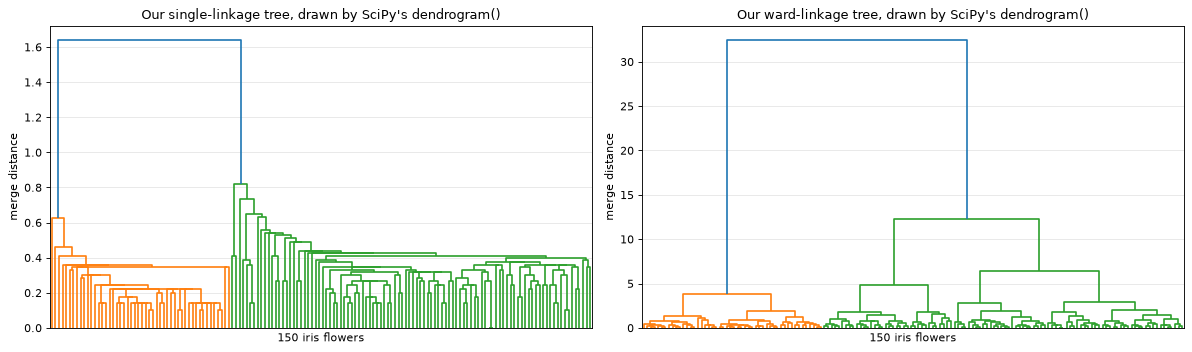

In [11]:
def lance_williams(method, d_ac, d_bc, d_ab, n_a, n_b, n_c):
    """Distance from the merged cluster (A ∪ B) to another cluster C, from distances already known.
    This one formula per linkage is what lets agglomerative clustering avoid recomputing point distances."""
    if method == "single":
        return min(d_ac, d_bc)                                   # closest pair
    if method == "complete":
        return max(d_ac, d_bc)                                   # farthest pair
    if method == "average":
        return (n_a * d_ac + n_b * d_bc) / (n_a + n_b)           # size-weighted average of the two averages
    if method == "ward":                                         # SciPy's form, on (not squared) distances
        total = n_a + n_b + n_c
        return np.sqrt(((n_a + n_c) * d_ac ** 2 + (n_b + n_c) * d_bc ** 2 - n_c * d_ab ** 2) / total)
    raise ValueError(method)


def agglomerative(X, method, point_distances=None):
    """Naive agglomerative clustering. Returns a SciPy-style linkage matrix: one row per merge,
    [id of cluster 1, id of cluster 2, merge distance, size of the new cluster].
    Points have ids 0..n-1; the cluster made by merge m gets id n + m.
    `point_distances` (optional, n x n) replaces the exact distances; only used for the rounding hurdle below."""
    n = len(X)
    D = np.full((2 * n - 1, 2 * n - 1), np.inf)              # room for all n points and all n-1 merged clusters
    D[:n, :n] = exact_distances(X) if point_distances is None else point_distances
    np.fill_diagonal(D, np.inf)                              # a cluster is never merged with itself
    size = np.zeros(2 * n - 1, dtype=int); size[:n] = 1
    alive = list(range(n))                                   # ids of the clusters that still exist
    Z = []
    for m in range(n - 1):
        sub = D[np.ix_(alive, alive)]                        # distances among living clusters only
        flat = np.argmin(sub)                                # the closest pair (first one, if there are ties)
        a, b = alive[flat // len(alive)], alive[flat % len(alive)]
        new = n + m
        for c in alive:                                      # distance from the new cluster to every other cluster
            if c not in (a, b):
                D[new, c] = D[c, new] = lance_williams(method, D[a, c], D[b, c], D[a, b], size[a], size[b], size[c])
        Z.append([min(a, b), max(a, b), D[a, b], size[a] + size[b]])
        size[new] = size[a] + size[b]
        alive = [c for c in alive if c not in (a, b)] + [new]
    return np.array(Z, dtype=float)


def cut_into_k(Z, k):
    """Flat clusters from a linkage matrix: replay the first n - k merges and label each point by its group."""
    n = len(Z) + 1
    members = {i: [i] for i in range(n)}                     # cluster id -> the points in it; starts as singletons
    for m, (a, b, _, _) in enumerate(Z[: n - k]):            # merge m joins clusters a and b into cluster n + m
        members[n + m] = members.pop(int(a)) + members.pop(int(b))
    labels = np.empty(n, dtype=int)
    for label, points in enumerate(members.values()):
        labels[points] = label
    return labels


iris_X = load_iris().data                                        # 150 flowers, 4 measurements, all in cm
print("method     largest merge-height difference vs SciPy   same 3-cluster partition (ARI = 1)   seconds (ours / SciPy)")
our_trees = {}
for method in ["single", "complete", "average", "ward"]:
    t0 = time.perf_counter(); Z_ours = agglomerative(iris_X, method); t_ours = time.perf_counter() - t0
    t0 = time.perf_counter(); Z_scipy = linkage(iris_X, method=method); t_scipy = time.perf_counter() - t0
    our_trees[method] = Z_ours
    height_gap = np.abs(np.sort(Z_ours[:, 2]) - np.sort(Z_scipy[:, 2])).max()
    same = adjusted_rand_score(cut_into_k(Z_ours, 3), fcluster(Z_scipy, 3, criterion="maxclust")) == 1.0
    print(f"{method:9s}  {height_gap:12.1e}                              {str(same):5s}"
          f"                              {t_ours:.2f} / {t_scipy:.4f}")
    assert height_gap < 1e-9 and same

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, method in zip(axes, ["single", "ward"]):
    dendrogram(our_trees[method], ax=ax, no_labels=True, color_threshold=None)
    ax.set_xlabel("150 iris flowers"); ax.set_ylabel("merge distance")
    ax.set_title(f"Our {method}-linkage tree, drawn by SciPy's dendrogram()")
plt.tight_layout(); plt.show()

> **How to read this**
> * For all four linkages, every merge height equals SciPy's (largest difference **1.8e-15**, rounding) and cutting the
>   tree into 3 clusters gives exactly SciPy's partition. The `assert` checks both.
> * Our trees, drawn with SciPy's `dendrogram()`. Single linkage shows the typical chaining: flowers join the two big
>   groups one at a time in a long staircase, and only setosa stands clearly apart. Ward splits setosa off at the top
>   (height about 32) and then the other two species (about 12): three groups.
> * Ours is far slower than SciPy (see the printed seconds; yours will differ). SciPy uses smarter algorithms (a
>   minimum spanning tree for single linkage, nearest-neighbour chains for the others) and compiled code.

> **Implementation hurdle — ties, and the rounding that decides them.** When two pairs are exactly equally close, which
> one is merged first is a free choice: the heights come out the same, but the rows of the linkage matrix can be in a
> different order. Measurements rounded to 0.1 cm produce *many* exact ties. And if distances are computed with the fast
> expansion trick, rounding errors decide the ties at random, which can produce a genuinely **different tree**.

In [12]:
# Two pairs at exactly the same distance: which pair is merged first is a tie
X_tie = np.array([[0.0, 0.0], [1.0, 0.0], [5.0, 0.0], [6.0, 0.0]])
print("ours :\n", agglomerative(X_tie, "single"))
print("SciPy:\n", linkage(X_tie, method="single"))
iris_rows_equal = {m: bool(np.allclose(our_trees[m], linkage(iris_X, method=m))) for m in our_trees}
print("\niris: linkage matrices identical row by row?", iris_rows_equal)

# Rounding decides ties: the fast distance trick is off by ~1e-15, enough to change which tied pair looks smaller
D_exact, D_fast = exact_distances(iris_X), pairwise_distances(iris_X, iris_X)
iu = np.triu_indices(len(iris_X), k=1)
values = D_exact[iu]
tied = len(values) - len(np.unique(values))
print(f"\niris has {len(values)} distinct pairs of flowers, and {tied} of their distances repeat an earlier value exactly")
print(f"largest gap between the fast and the exact distances: {np.abs(D_exact - D_fast).max():.1e}")
Z_fast = agglomerative(iris_X, "complete", point_distances=D_fast)
print("complete linkage built from the FAST distances: largest merge-height difference vs SciPy "
      f"{np.abs(np.sort(Z_fast[:, 2]) - np.sort(linkage(iris_X, 'complete')[:, 2])).max():.3f}")

ours :
 [[0. 1. 1. 2.]
 [2. 3. 1. 2.]
 [4. 5. 4. 4.]]
SciPy:
 [[0. 1. 1. 2.]
 [2. 3. 1. 2.]
 [4. 5. 4. 4.]]

iris: linkage matrices identical row by row? {'single': False, 'complete': False, 'average': True, 'ward': False}

iris has 11175 distinct pairs of flowers, and 5611 of their distances repeat an earlier value exactly
largest gap between the fast and the exact distances: 1.7e-07


complete linkage built from the FAST distances: largest merge-height difference vs SciPy 0.116


> **How to read this**
> * The tiny example (two pairs at distance exactly 1) happens to merge in the same order as SciPy.
> * On iris, the linkage matrices are identical **row by row** only for average linkage; for single, complete and ward
>   the tied merges come in a different order. The heights and the 3-cluster partitions are still identical (cell
>   above).
> * Iris has **11175** pairs of flowers, and **5611** of their distances repeat an earlier value exactly.
> * The fast distances differ from the exact ones by up to **1.7e-7**, which is enough to break those ties differently:
>   complete linkage built from them gives merge heights up to **0.116** away from SciPy's. That's why the tree,
>   DBSCAN and OPTICS use `exact_distances`.

---

<a id="sec-4"></a>

## 4 · DBSCAN

**README §5.** Two settings: a radius `eps` and a count `min_samples`.

1. The **neighbourhood** of a point is every point within distance `eps`, **including the point itself**
   (scikit-learn's convention).
2. A **core point** has at least `min_samples` points in its neighbourhood.
3. Go through the points in index order. Each core point not yet in a cluster starts a new cluster, which grows
   **breadth-first**: every core point in the cluster adds its whole neighbourhood. A non-core point that gets added is
   a **border point**: it belongs, but its own neighbours are not added through it.
4. Points never added to any cluster are **noise** (label −1).

Data: the two moons plus 20 stray points from library Lab 7.

ours        : 2 clusters, 402 core, 13 noise
scikit-learn: 2 clusters, 402 core, 13 noise
identical labels: True | identical core points: True


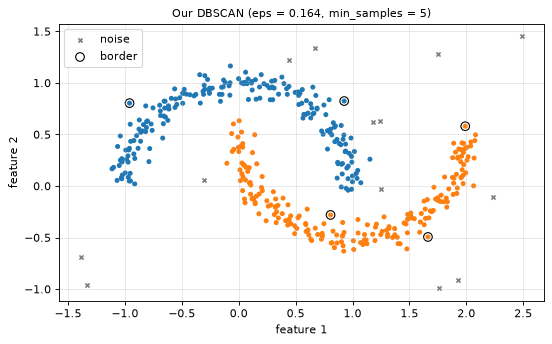

In [13]:
def dbscan(X, eps, min_samples):
    """DBSCAN. Returns (labels with -1 = noise, boolean core-point mask).

    1. Neighbourhood of a point = all points within distance eps, INCLUDING the point itself.
    2. Core point = neighbourhood holds at least `min_samples` points.
    3. Go through the points in order; every unlabelled core point starts a new cluster, which grows outwards
       (breadth-first) through core points. Non-core points reached on the way join as border points but don't
       spread the cluster further. Points never reached stay noise."""
    D = exact_distances(X)
    neighbours = [np.flatnonzero(D[i] <= eps) for i in range(len(X))]     # step 1
    core = np.array([len(nb) >= min_samples for nb in neighbours])        # step 2
    labels = np.full(len(X), -1)                                           # everyone starts as noise
    cluster = 0
    for i in range(len(X)):                                                # step 3
        if labels[i] != -1 or not core[i]:
            continue                                                       # already clustered, or not a seed
        labels[i] = cluster
        queue = deque([i])
        while queue:
            p = queue.popleft()
            if not core[p]:
                continue                                                   # border point: belongs, doesn't spread
            for q in neighbours[p]:
                if labels[q] == -1:                                        # unclaimed (noise so far) -> claim it
                    labels[q] = cluster
                    queue.append(q)
        cluster += 1
    return labels, core


X_db, _ = make_moons(400, noise=0.07, random_state=SEED)
X_db = np.vstack([X_db, np.random.default_rng(SEED).uniform([-1.5, -1], [2.5, 1.5], size=(20, 2))])   # + 20 strays
labels_db, core_db = dbscan(X_db, eps=0.164, min_samples=5)
reference = DBSCAN(eps=0.164, min_samples=5).fit(X_db)
print(f"ours        : {labels_db.max() + 1} clusters, {core_db.sum()} core, {(labels_db == -1).sum()} noise")
print(f"scikit-learn: {reference.labels_.max() + 1} clusters, {len(reference.core_sample_indices_)} core, "
      f"{(reference.labels_ == -1).sum()} noise")
print("identical labels:", np.array_equal(labels_db, reference.labels_),
      "| identical core points:", np.array_equal(np.flatnonzero(core_db), reference.core_sample_indices_))
assert np.array_equal(labels_db, reference.labels_)

fig, ax = plt.subplots(figsize=(7, 4.4))
plot_clusters(ax, X_db, labels_db, "Our DBSCAN (eps = 0.164, min_samples = 5)")
ax.scatter(*X_db[(labels_db != -1) & ~core_db].T, s=60, facecolors="none", edgecolors="k", label="border")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Ours and scikit-learn's agree exactly: **2** clusters, **402** core points, **13** noise points, the same label for
>   every point and the same list of core points.
> * The circled points are border points: inside a cluster, but not dense enough to extend it.

> **Implementation hurdle — a border point next to two clusters.** A border point can lie within `eps` of core points
> from **two** different clusters. It still gets only one label: that of whichever cluster reaches it first. The
> original notes said "assign it to the nearest core point's cluster", which is a sensible alternative, but neither
> the original DBSCAN paper nor scikit-learn does that: the result depends on the **order** of the points. Below,
> point 4 sits exactly between two clusters.

In [14]:
# A border point within eps of core points from TWO clusters: it can only get one label
X_border = np.array([[0.0, 0], [0.3, 0], [0.6, 0], [0.9, 0],     # left cluster (points 0-3, all core)
                     [1.8, 0],                                  # point 4: only 3 neighbours, so a border point
                     [2.7, 0], [3.0, 0], [3.3, 0], [3.6, 0]])   # right cluster (points 5-8, all core)
EPS, MIN_SAMPLES = 0.95, 4
labels_fwd, core_b = dbscan(X_border, EPS, MIN_SAMPLES)
print("core points:", np.flatnonzero(core_b), "| point 4 is core?", core_b[4])
print("points in the original order :", labels_fwd, "-> point 4 joined the",
      "left" if labels_fwd[4] == labels_fwd[0] else "right", "cluster")
reverse = np.arange(len(X_border))[::-1]                         # the same points, listed right to left
labels_rev_listed, _ = dbscan(X_border[reverse], EPS, MIN_SAMPLES)
labels_rev = np.empty(len(X_border), dtype=int); labels_rev[reverse] = labels_rev_listed   # back to original order
print("points in the reversed order:", labels_rev, "-> point 4 joined the",
      "left" if labels_rev[4] == labels_rev[0] else "right", "cluster")
print("scikit-learn, original order :", DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_border))

core points: [0 1 2 3 5 6 7 8] | point 4 is core? False
points in the original order : [0 0 0 0 0 1 1 1 1] -> point 4 joined the left cluster
points in the reversed order: [1 1 1 1 0 0 0 0 0] -> point 4 joined the right cluster
scikit-learn, original order : [0 0 0 0 0 1 1 1 1]


> **How to read this**
> * Point 4 has only 3 points in its neighbourhood (itself and one point from each side), so with `min_samples` = 4 it
>   is not a core point, while all the others are.
> * Points listed left to right: the left cluster is built first and claims point 4. The same points listed right to
>   left: the right cluster claims it.
> * scikit-learn gives the same answer as ours in the original order. Core points and noise never depend on the order;
>   only border points can.

---

<a id="sec-5"></a>

## 5 · OPTICS

**README §6.** OPTICS answers "what would DBSCAN give at *every* eps?" in one pass.

* **Core distance** of $p$: distance to its `min_samples`-th nearest neighbour, counting $p$ itself. The smallest
  eps at which $p$ would be a core point.
* **Reachability distance** of $o$ from $p$: $\max\big(\text{core distance}(p),\ d(p, o)\big)$.
* **The loop:** take the unvisited point with the smallest reachability so far (the lowest index if several tie, or if
  all are still infinite, which is how a new region starts). Record it in the **ordering**. If it is a core point,
  lower the reachability of each unvisited point to its reachability through this point, when that is smaller.

Plotting reachability in visiting order gives the reachability plot: valleys are clusters. `clusters_at_eps` turns one
horizontal cut into DBSCAN-style labels: walking in order, a point with reachability above eps that is itself a core
point at that eps starts a new cluster; a point that is neither is noise. Same data as section 4.

same ordering: True | same predecessors: True
largest difference: reachability 4.996003610813204e-16 | core distance 4.996003610813204e-16
time: ours 0.008 s, scikit-learn 0.152 s
cut at eps 0.100:  5 clusters,   8% noise | same as sklearn's cut: True | agreement with DBSCAN at that eps: ARI 0.998
cut at eps 0.164:  2 clusters,   3% noise | same as sklearn's cut: True | agreement with DBSCAN at that eps: ARI 1.000
cut at eps 0.500:  1 clusters,   1% noise | same as sklearn's cut: True | agreement with DBSCAN at that eps: ARI 1.000


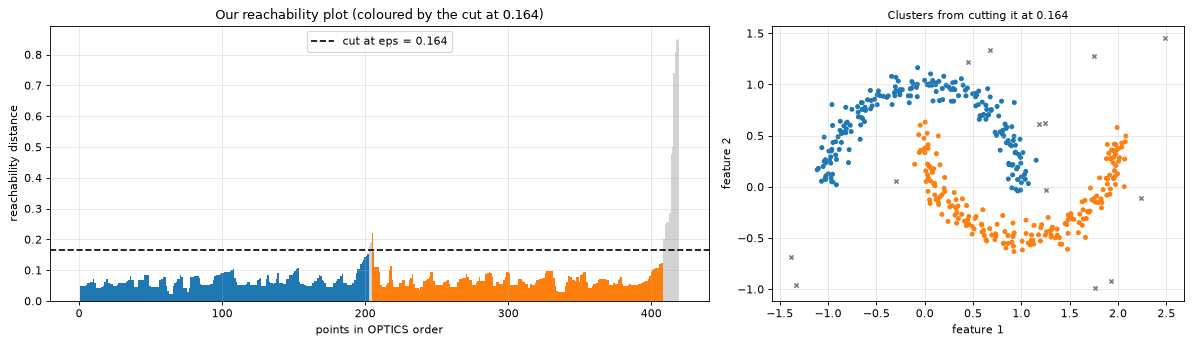

In [15]:
def optics(X, min_samples, max_eps=np.inf):
    """OPTICS. Returns (ordering, reachability, core_distances, predecessor), each indexed like scikit-learn.

    core distance(p)    = distance to p's min_samples-th nearest neighbour, counting p itself
    reachability(o, p)  = max(core distance(p), d(p, o))
    Loop: take the unvisited point with the SMALLEST reachability so far (the lowest index if several tie, or if
    all are still infinite), record it, and lower the reachability of its unvisited neighbours through it."""
    n = len(X)
    D = exact_distances(X)
    core_dist = np.sort(D, axis=1)[:, min_samples - 1]           # column 0 is the point itself (distance 0)
    core_dist[core_dist > max_eps] = np.inf                       # too far: not a core point at any eps <= max_eps
    reach = np.full(n, np.inf)                                    # best reachability found so far for each point
    predecessor = np.full(n, -1)                                  # which point gave that reachability
    visited = np.zeros(n, dtype=bool)
    ordering = []
    for _ in range(n):
        candidates = np.flatnonzero(~visited)
        p = candidates[np.argmin(reach[candidates])]              # argmin picks the lowest index among ties
        visited[p] = True
        ordering.append(p)
        if np.isinf(core_dist[p]):
            continue                                              # not a core point: it can't reach anyone
        others = np.flatnonzero(~visited & (D[p] <= max_eps))     # unvisited points within max_eps of p
        through_p = np.maximum(core_dist[p], D[p, others])        # their reachability if reached from p
        better = through_p < reach[others]                        # only ever lower a reachability
        reach[others[better]] = through_p[better]
        predecessor[others[better]] = p
    return np.array(ordering), reach, core_dist, predecessor


def clusters_at_eps(ordering, reach, core_dist, eps):
    """DBSCAN-style clusters from an OPTICS run, by cutting the reachability plot at height eps.
    Walking in OPTICS order, a point that is far from everything visited so far (reach > eps) but is itself a
    core point at this eps starts a new cluster; a point that is neither close nor core is noise."""
    far = reach > eps
    core_here = core_dist <= eps
    labels = np.zeros(len(reach), dtype=int)
    labels[ordering] = np.cumsum(far[ordering] & core_here[ordering]) - 1   # cluster number goes up at each start
    labels[far & ~core_here] = -1
    return labels


t0 = time.perf_counter(); order, reach, core_d, pred = optics(X_db, min_samples=5); t_ours = time.perf_counter() - t0
t0 = time.perf_counter(); reference = OPTICS(min_samples=5).fit(X_db); t_sk = time.perf_counter() - t0
finite = ~np.isinf(reach)
print("same ordering:", np.array_equal(order, reference.ordering_),
      "| same predecessors:", np.array_equal(pred, reference.predecessor_))
print("largest difference: reachability", np.abs(reach[finite] - reference.reachability_[finite]).max(),
      "| core distance", np.abs(core_d - reference.core_distances_).max())
print(f"time: ours {t_ours:.3f} s, scikit-learn {t_sk:.3f} s")
for eps in [0.1, 0.164, 0.5]:
    ours = clusters_at_eps(order, reach, core_d, eps)
    theirs = cluster_optics_dbscan(reachability=reference.reachability_, core_distances=reference.core_distances_,
                                   ordering=reference.ordering_, eps=eps)
    direct = DBSCAN(eps=eps, min_samples=5).fit_predict(X_db)
    print(f"cut at eps {eps:5.3f}: {ours.max() + 1:2d} clusters, {np.mean(ours == -1):4.0%} noise | same as sklearn's "
          f"cut: {np.array_equal(ours, theirs)} | agreement with DBSCAN at that eps: ARI {adjusted_rand_score(direct, ours):.3f}")
assert np.array_equal(order, reference.ordering_)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
labels_cut = clusters_at_eps(order, reach, core_d, 0.164)
colors = ["lightgray" if label == -1 else plt.cm.tab10(label % 10) for label in labels_cut[order]]
axes[0].bar(range(len(order)), np.where(np.isinf(reach[order]), np.nan, reach[order]), color=colors, width=1.0)
axes[0].axhline(0.164, color="black", ls="--", label="cut at eps = 0.164")
axes[0].set_xlabel("points in OPTICS order"); axes[0].set_ylabel("reachability distance")
axes[0].set_title("Our reachability plot (coloured by the cut at 0.164)"); axes[0].legend()
plot_clusters(axes[1], X_db, labels_cut, "Clusters from cutting it at 0.164")
plt.tight_layout(); plt.show()

> **How to read this**
> * Same **ordering** and same **predecessors** (which point each one was reached from) as scikit-learn; reachability
>   and core distances agree to **5e-16**.
> * Our version is faster here (see the printed times) only because it holds the full 420 × 420 distance matrix in memory.
>   scikit-learn uses a neighbour search instead, which scales to data where an n × n matrix wouldn't fit.
> * **Cutting our reachability plot** at eps = 0.1, 0.164 and 0.5 gives exactly scikit-learn's `cluster_optics_dbscan`
>   labels, and matches running DBSCAN at that eps: ARI **1.000** at 0.164 and 0.5, **0.998** at 0.1 (a border point or
>   two can land differently). At 0.1 the moons shatter into 5 clusters; at 0.5 they merge into 1.

> **Implementation hurdle — the "smallest reachability so far" queue.** Textbook OPTICS keeps unvisited points in a
> priority queue (a heap) and *lowers* a point's key when a better reachability is found. Python's `heapq` has no
> "lower a key" operation. The standard workaround: push a **new** entry with the lower value and, when popping, skip
> entries whose point was already visited ("lazy deletion"). Ties must also be broken the same way (by point index) to
> reproduce the same ordering.

In [16]:
def optics_heap(X, min_samples):
    """The same OPTICS loop, but the next point comes from a heap (priority queue) instead of an argmin over all
    unvisited points. Python's heapq can't lower a key, so a lowered reachability is pushed as a NEW entry and
    stale entries (for points already visited) are skipped when popped ("lazy deletion")."""
    n = len(X)
    D = exact_distances(X)
    core_dist = np.sort(D, axis=1)[:, min_samples - 1]
    reach = np.full(n, np.inf)
    visited = np.zeros(n, dtype=bool)
    ordering, heap, next_start = [], [], 0
    while len(ordering) < n:
        while heap and visited[heap[0][1]]:
            heapq.heappop(heap)                                   # throw away stale entries
        if heap:
            _, p = heapq.heappop(heap)                            # smallest (reachability, index) pair
        else:                                                     # nothing reachable: start at the next unvisited
            while visited[next_start]:
                next_start += 1
            p = next_start
        visited[p] = True
        ordering.append(p)
        others = np.flatnonzero(~visited)
        through_p = np.maximum(core_dist[p], D[p, others])
        for q, r in zip(others[through_p < reach[others]], through_p[through_p < reach[others]]):
            reach[q] = r
            heapq.heappush(heap, (r, q))                          # ties broken by index, like argmin
    return np.array(ordering), reach


t0 = time.perf_counter(); order_heap, reach_heap = optics_heap(X_db, 5); t_heap = time.perf_counter() - t0
print("heap version: same ordering as the argmin version:", np.array_equal(order_heap, order),
      "| same reachability:", np.allclose(np.nan_to_num(reach_heap, posinf=0), np.nan_to_num(reach, posinf=0)))
print(f"time on {len(X_db)} points: argmin version {t_ours:.3f} s, heap version {t_heap:.3f} s")

heap version: same ordering as the argmin version: True | same reachability: True
time on 420 points: argmin version 0.008 s, heap version 0.013 s


> **How to read this**
> * The heap version gives the **same ordering and reachability** as the argmin version (and therefore as
>   scikit-learn).
> * It isn't faster here (see the printed times): with a full distance matrix both versions look at every unvisited point
>   at every step, so both cost about $n^2$, and NumPy's `argmin` is quicker than a Python heap loop. The heap pays off
>   when each point only has a few neighbours to update (a neighbour index plus a finite `max_eps`).

---

<a id="summary"></a>

## Summary

| Section | Our implementation | Matches the library? | Hurdle shown |
|---|---|---|---|
| [1](#sec-1) | k-means: `assign`, `update`, `kmeans`; k-means++ | ✔ identical labels, inertia and iteration count | empty clusters (NaN); n × k × d memory blow-up |
| [1](#sec-1) | k-means++ | ✔ same idea; sklearn's greedy variant is a bit better (29 % vs 50 % best runs) | — |
| [1 · toy](#toy) | exact toy, 3 pairs: all random starts and exact k-means++ probabilities | ✔ all 20 starts match `KMeans`; Monte Carlo agrees | random init stuck 20 % of the time, at (2/3)[1 + (1 + r)²] × the optimum |
| [2](#sec-2) | silhouette, chord-rule elbow | ✔ silhouette equal at every k | — |
| [3](#sec-3) | agglomerative with Lance–Williams, 4 linkages | ✔ identical merge heights and partitions | ties: row order; rounding changes the tree |
| [4](#sec-4) | DBSCAN | ✔ identical labels and core points | border point between two clusters depends on order |
| [5](#sec-5) | OPTICS, `clusters_at_eps` | ✔ identical ordering, reachability, predecessors and cuts | priority queue without decrease-key |